# Cryptocurrency Volatility Prediction — End-to-End ML Notebook

**Project:** BTC, ETH, BNB and SOL volatility forecasting  
**Task:** Regression — predict the standard deviation of the *next 7 daily log returns* for each cryptocurrency.

This notebook covers data loading, cleaning, leakage-safe feature engineering, chronological train/validation/test splitting, model training, evaluation, visualization and model export.

## Before running
1. Put your combined CSV at `data/raw/data.csv` (or update `DATA_PATH` below).
2. Expected columns: `date`, `open`, `high`, `low`, `close`, `volume`, `marketCap`, `crypto_name`.
3. Run the notebook from top to bottom.

The code also accepts common capitalization variants such as `Date`, `Close`, and `Market Cap`.


## 1. Imports and configuration

In [5]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import joblib

RANDOM_STATE = 42
DATA_PATH = Path("C:/Users/Mayur/CRYPTOCURRECNY VOLATILITY PROJECT/data/raw/data.csv")  # Change this if your CSV is elsewhere
OUTPUT_DIR = Path("artifacts")
MODEL_DIR = Path("models")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)
print("Configuration ready.")

Configuration ready.


## 2. Load the dataset

In [6]:
if not DATA_PATH.exists():
    candidates = list(Path(".").glob("*.csv")) + list(Path("data").rglob("*.csv"))
    if candidates:
        print("CSV files found:")
        for i, path in enumerate(candidates[:20]):
            print(f"{i}: {path}")
        raise FileNotFoundError(
            f"Set DATA_PATH to the correct CSV file. Current value: {DATA_PATH}"
        )
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH}. Place your combined CSV there or update DATA_PATH."
    )

df_raw = pd.read_csv(DATA_PATH)
print("Shape:", df_raw.shape)
display(df_raw.head())
print("\nColumns:", df_raw.columns.tolist())

Shape: (72946, 10)


,Unnamed: 0,open,high,low,close,volume,marketCap,timestamp,crypto_name,date
0,0,112.900002,118.800003,107.142998,115.910004,0.0,1.288693e+09,2013-05-05T23:59:59.999Z,Bitcoin,2013-05-05
1,1,3.493130,3.692460,3.346060,3.590890,0.0,6.229819e+07,2013-05-05T23:59:59.999Z,Litecoin,2013-05-05
2,2,115.980003,124.663002,106.639999,112.300003,0.0,1.249023e+09,2013-05-06T23:59:59.999Z,Bitcoin,2013-05-06
3,3,3.594220,3.781020,3.116020,3.371250,0.0,5.859436e+07,2013-05-06T23:59:59.999Z,Litecoin,2013-05-06
4,4,112.250000,113.444000,97.699997,111.500000,0.0,1.240594e+09,2013-05-07T23:59:59.999Z,Bitcoin,2013-05-07



Columns: ['Unnamed: 0', 'open', 'high', 'low', 'close', 'volume', 'marketCap', 'timestamp', 'crypto_name', 'date']


## 3. Standardize column names and clean data

In [7]:
# Normalize common column-name variations
rename_map = {}
for col in df_raw.columns:
    key = str(col).strip().lower().replace(" ", "").replace("_", "")
    mapping = {
        "date": "date", "timestamp": "timestamp",
        "open": "open", "high": "high", "low": "low", "close": "close",
        "volume": "volume", "marketcap": "marketCap",
        "cryptoname": "crypto_name", "symbol": "crypto_name",
        "unnamed:0": "drop_index"
    }
    if key in mapping:
        rename_map[col] = mapping[key]

df = df_raw.rename(columns=rename_map).copy()
if "drop_index" in df.columns:
    df = df.drop(columns=["drop_index"])

# Use date when present; otherwise derive it from timestamp
if "date" in df.columns:
    df["date"] = pd.to_datetime(df["date"], errors="coerce", utc=True).dt.tz_localize(None)
elif "timestamp" in df.columns:
    ts = pd.to_datetime(df["timestamp"], errors="coerce", utc=True)
    if ts.isna().mean() > 0.5:
        # Some datasets store Unix timestamps in seconds or milliseconds
        numeric_ts = pd.to_numeric(df["timestamp"], errors="coerce")
        unit = "ms" if numeric_ts.dropna().median() > 1e11 else "s"
        ts = pd.to_datetime(numeric_ts, unit=unit, errors="coerce", utc=True)
    df["date"] = ts.dt.tz_localize(None)
else:
    raise ValueError("A 'date' or 'timestamp' column is required.")

required = ["open", "high", "low", "close", "volume"]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing required price columns: {missing}")

if "crypto_name" not in df.columns:
    df["crypto_name"] = "UNKNOWN"

numeric_cols = ["open", "high", "low", "close", "volume"]
if "marketCap" in df.columns:
    numeric_cols.append("marketCap")

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["crypto_name"] = df["crypto_name"].astype(str).str.upper().str.strip()
df = df.dropna(subset=["date", "close", "open", "high", "low"])
df = df[df["close"] > 0].copy()
df = df.sort_values(["crypto_name", "date"]).drop_duplicates(
    subset=["crypto_name", "date"], keep="last"
).reset_index(drop=True)

print("Cleaned shape:", df.shape)
print("Assets:", sorted(df["crypto_name"].unique()))
display(df.isna().sum().to_frame("missing_values"))

Cleaned shape: (72946, 9)
Assets: ['AAVE', 'ALGORAND', 'APECOIN', 'APTOS', 'AVALANCHE', 'BASIC ATTENTION TOKEN', 'BINANCE USD', 'BITCOIN', 'BITCOIN CASH', 'BNB', 'CARDANO', 'CASPER', 'CHAIN', 'CHAINLINK', 'CHILIZ', 'COSMOS', 'CRONOS', 'DAI', 'DECENTRALAND', 'DOGECOIN', 'ELROND', 'EOS', 'ETHEREUM', 'ETHEREUM CLASSIC', 'FILECOIN', 'FLOW', 'FTX TOKEN', 'HEDERA', 'HUOBI TOKEN', 'INTERNET COMPUTER', 'LITECOIN', 'MAKER', 'MONERO', 'NEAR PROTOCOL', 'OKB', 'POLKADOT', 'POLYGON', 'QUANT', 'RAVENCOIN', 'SHIBA INU', 'SOLANA', 'STELLAR', 'TERRA CLASSIC', 'TETHER', 'TEZOS', 'THE SANDBOX', 'THETA NETWORK', 'THORCHAIN', 'TONCOIN', 'TRON', 'UNISWAP', 'UNUS SED LEO', 'USD COIN', 'VECHAIN', 'WRAPPED BITCOIN', 'XRP']


,missing_values
open,0
high,0
low,0
close,0
volume,0
marketCap,0
timestamp,0
crypto_name,0
date,0


## 4. Exploratory data analysis

                       rows start_date   end_date     min_close     max_close
crypto_name                                                                  
AAVE                    547 2020-10-02 2022-10-23  5.165715e-01    632.266488
ALGORAND               1010 2019-06-21 2022-10-23  1.264714e-01      3.201412
APECOIN                  80 2022-03-17 2022-10-23  3.630507e+00     19.439499
APTOS                     1 2022-10-23 2022-10-23  9.768685e+00      9.768685
AVALANCHE               559 2020-07-13 2022-10-23  2.906161e+00    134.531030
BASIC ATTENTION TOKEN  1760 2017-06-01 2022-10-23  7.178100e-02      1.766300
BINANCE USD             919 2019-09-20 2022-10-23  9.700063e-01      1.052356
BITCOIN                3248 2013-05-05 2022-10-23  6.843100e+01  67566.830088
BITCOIN CASH           1708 2017-07-23 2022-10-23  7.736578e+01   3923.070068
BNB                    1706 2017-07-25 2022-10-23  9.986680e-02    675.684077
CARDANO                1638 2017-10-01 2022-10-23  1.853910e-02 

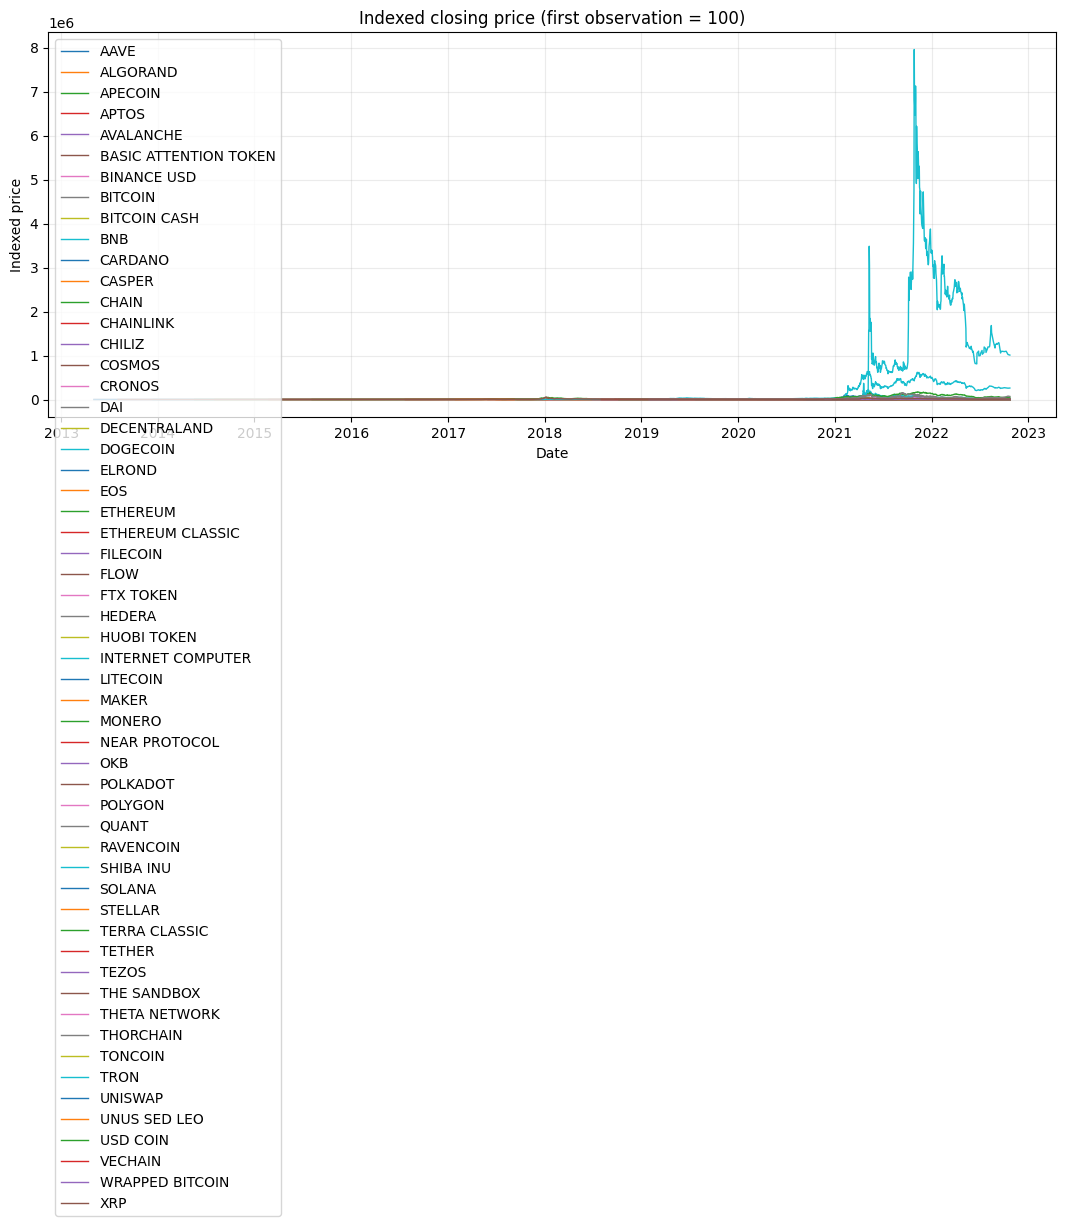

In [8]:
print(df.groupby("crypto_name").agg(
    rows=("close", "size"),
    start_date=("date", "min"),
    end_date=("date", "max"),
    min_close=("close", "min"),
    max_close=("close", "max")
))

fig, ax = plt.subplots(figsize=(13, 5))
for name, group in df.groupby("crypto_name"):
    group = group.sort_values("date")
    # Indexed close makes assets with different price scales easier to compare
    indexed = group["close"] / group["close"].iloc[0] * 100
    ax.plot(group["date"], indexed, label=name, linewidth=1)
ax.set_title("Indexed closing price (first observation = 100)")
ax.set_xlabel("Date")
ax.set_ylabel("Indexed price")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 5. Feature engineering and target construction

Features use information available on the current date and earlier dates only. The target is calculated from the **following seven daily log returns**, so the model learns to forecast future volatility rather than describe past volatility.

The target at date *t* is the sample standard deviation of returns at *t+1 ... t+7*. The final seven observations per asset naturally have no target and are removed.

In [9]:
def add_features(group):
    group = group.sort_values("date").copy()

    close = group["close"]
    high = group["high"]
    low = group["low"]
    volume = group["volume"]

    # Returns
    group["log_return"] = np.log(close / close.shift(1))
    group["daily_return"] = close.pct_change()

    # Rolling return statistics (historical, including current day)
    for window in [3, 7, 14, 30]:
        group[f"return_mean_{window}"] = group["log_return"].rolling(window).mean()
        group[f"return_vol_{window}"] = group["log_return"].rolling(window).std()

    # Moving averages and price ratios
    for window in [7, 14, 30]:
        group[f"sma_{window}"] = close.rolling(window).mean()
        group[f"close_sma_ratio_{window}"] = close / group[f"sma_{window}"]

    group["ema_12"] = close.ewm(span=12, adjust=False).mean()
    group["ema_26"] = close.ewm(span=26, adjust=False).mean()
    group["macd"] = group["ema_12"] - group["ema_26"]
    group["macd_signal"] = group["macd"].ewm(span=9, adjust=False).mean()

    # RSI (14)
    delta = close.diff()
    gain = delta.clip(lower=0).rolling(14).mean()
    loss = (-delta.clip(upper=0)).rolling(14).mean()
    rs = gain / loss.replace(0, np.nan)
    group["rsi_14"] = 100 - (100 / (1 + rs))

    # Bollinger Bands (20)
    rolling_mean = close.rolling(20).mean()
    rolling_std = close.rolling(20).std()
    group["bb_width_20"] = (4 * rolling_std) / rolling_mean.replace(0, np.nan)
    group["bb_position_20"] = (close - (rolling_mean - 2 * rolling_std)) / (4 * rolling_std).replace(0, np.nan)

    # Average True Range (14)
    previous_close = close.shift(1)
    true_range = pd.concat([
        high - low,
        (high - previous_close).abs(),
        (low - previous_close).abs()
    ], axis=1).max(axis=1)
    group["atr_14"] = true_range.rolling(14).mean()
    group["atr_pct"] = group["atr_14"] / close

    # Volume features
    group["volume_change"] = volume.pct_change().replace([np.inf, -np.inf], np.nan)
    group["volume_mean_7"] = volume.rolling(7).mean()
    group["volume_ratio_7"] = volume / group["volume_mean_7"].replace(0, np.nan)

    # Lagged returns
    for lag in [1, 2, 3, 7]:
        group[f"return_lag_{lag}"] = group["log_return"].shift(lag)

    # Future 7-day realized volatility: returns t+1 through t+7.
    future_returns = group["log_return"].shift(-1)
    group["target_volatility_7d"] = future_returns.rolling(7).std().shift(-6)

    return group

data = (
    df.groupby("crypto_name", group_keys=False)
      .apply(add_features)
      .replace([np.inf, -np.inf], np.nan)
      .reset_index(drop=True)
)

data = data.dropna(subset=["target_volatility_7d"]).copy()
print("Feature-engineered shape:", data.shape)
print("Target summary:")
display(data["target_volatility_7d"].describe().to_frame())
display(data[["date", "crypto_name", "close", "log_return", "return_vol_7", "target_volatility_7d"]].tail())

Feature-engineered shape: (72560, 42)
Target summary:


,target_volatility_7d
count,72560.000000
mean,0.057435
std,0.060534
min,0.000000
25%,0.028170
50%,0.047268
75%,0.073141
max,3.195219


,date,crypto_name,close,log_return,return_vol_7,target_volatility_7d
72934,2022-08-29,XRP,0.333797,0.032587,0.042840,0.088335
72935,2022-09-04,XRP,0.331799,-0.006003,0.040801,0.103314
72936,2022-09-05,XRP,0.332960,0.003493,0.041459,0.112097
72937,2022-09-11,XRP,0.355119,0.064431,0.051893,0.131313
72938,2022-09-12,XRP,0.359445,0.012109,0.039536,0.132865


## 6. Select features and prepare chronological splits

We split by unique calendar dates, not random rows. This prevents observations from the same date being scattered across train and test sets. The most recent 15% of dates are held out for final testing; the preceding 15% are validation dates.

In [10]:
excluded = {
    "date", "timestamp", "target_volatility_7d",
    "open", "high", "low", "close", "volume", "marketCap"
}
# Use engineered features and crypto identity; raw price levels are excluded.
feature_cols = [
    c for c in data.columns
    if c not in excluded and c not in {"ema_12", "ema_26"} 
]
# Ensure asset identity is included as a categorical predictor
if "crypto_name" not in feature_cols:
    feature_cols.append("crypto_name")

X = data[feature_cols].copy()
y = data["target_volatility_7d"].copy()

unique_dates = np.array(sorted(data["date"].dropna().unique()))
n_dates = len(unique_dates)
if n_dates < 30:
    raise ValueError("Not enough unique dates for reliable chronological train/validation/test splits.")

train_end = unique_dates[int(n_dates * 0.70) - 1]
valid_end = unique_dates[int(n_dates * 0.85) - 1]

train_mask = data["date"] <= train_end
valid_mask = (data["date"] > train_end) & (data["date"] <= valid_end)
test_mask = data["date"] > valid_end

X_train, y_train = X.loc[train_mask], y.loc[train_mask]
X_valid, y_valid = X.loc[valid_mask], y.loc[valid_mask]
X_test, y_test = X.loc[test_mask], y.loc[test_mask]

print(f"Train:      {X_train.shape}, through {train_end}")
print(f"Validation: {X_valid.shape}, through {valid_end}")
print(f"Test:       {X_test.shape}, after {valid_end}")
print("Feature count:", len(feature_cols))
print("Numeric features:", X.select_dtypes(include=np.number).columns.tolist())
print("Categorical features:", X.select_dtypes(exclude=np.number).columns.tolist())

Train:      (27207, 31), through 2019-07-20 00:00:00
Validation: (20022, 31), through 2020-11-24 00:00:00
Test:       (25331, 31), after 2020-11-24 00:00:00
Feature count: 31
Numeric features: ['log_return', 'daily_return', 'return_mean_3', 'return_vol_3', 'return_mean_7', 'return_vol_7', 'return_mean_14', 'return_vol_14', 'return_mean_30', 'return_vol_30', 'sma_7', 'close_sma_ratio_7', 'sma_14', 'close_sma_ratio_14', 'sma_30', 'close_sma_ratio_30', 'macd', 'macd_signal', 'rsi_14', 'bb_width_20', 'bb_position_20', 'atr_14', 'atr_pct', 'volume_change', 'volume_mean_7', 'volume_ratio_7', 'return_lag_1', 'return_lag_2', 'return_lag_3', 'return_lag_7']
Categorical features: ['crypto_name']


## 7. Build preprocessing and model pipelines

In [11]:
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

def make_preprocessor(scale_numeric=False):
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))

    transformers = [
        ("numeric", Pipeline(numeric_steps), numeric_features)
    ]
    if categorical_features:
        transformers.append((
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_features
        ))
    return ColumnTransformer(transformers, remainder="drop")

models = {
    "Linear Regression": Pipeline([
        ("preprocessor", make_preprocessor(scale_numeric=True)),
        ("model", LinearRegression())
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", RandomForestRegressor(
            n_estimators=300, max_depth=16, min_samples_leaf=2,
            random_state=RANDOM_STATE, n_jobs=-1
        ))
    ]),
    "Extra Trees": Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", ExtraTreesRegressor(
            n_estimators=300, max_depth=16, min_samples_leaf=2,
            random_state=RANDOM_STATE, n_jobs=-1
        ))
    ])
}

# XGBoost is optional. The notebook still runs if it is not installed.
try:
    from xgboost import XGBRegressor
    models["XGBoost"] = Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", XGBRegressor(
            n_estimators=500, max_depth=5, learning_rate=0.03,
            subsample=0.85, colsample_bytree=0.85,
            objective="reg:squarederror", random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])
    print("XGBoost is available and added.")
except ImportError:
    print("XGBoost is not installed; skipping it. Install with: pip install xgboost")

print("Models:", list(models.keys()))

XGBoost is available and added.
Models: ['Linear Regression', 'Random Forest', 'Extra Trees', 'XGBoost']


## 8. Train models and compare validation performance

In [12]:
def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

validation_results = []
fitted_models = {}

for name, pipeline in models.items():
    print(f"Training {name} ...")
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_valid)
    metrics = regression_metrics(y_valid, predictions)
    validation_results.append({"Model": name, **metrics})
    fitted_models[name] = pipeline

validation_results = pd.DataFrame(validation_results).sort_values("RMSE")
display(validation_results)
best_name = validation_results.iloc[0]["Model"]
print("Best validation model:", best_name)

Training Linear Regression ...
Training Random Forest ...
Training Extra Trees ...
Training XGBoost ...


,Model,MAE,RMSE,R2
3,XGBoost,0.021625,0.037543,0.314997
1,Random Forest,0.022106,0.038917,0.263941
0,Linear Regression,0.023976,0.039722,0.233152
2,Extra Trees,0.023800,0.040007,0.222127


Best validation model: XGBoost


## 9. Final test evaluation

After selecting the model using validation data, evaluate it on the untouched test period. The test set is not used for model selection.

In [13]:
best_model = fitted_models[best_name]
test_predictions = best_model.predict(X_test)

test_metrics = regression_metrics(y_test, test_predictions)
print("Final test metrics")
for metric, value in test_metrics.items():
    print(f"{metric}: {value:.6f}")

comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": test_predictions
}, index=y_test.index)
comparison["Absolute_Error"] = (comparison["Actual"] - comparison["Predicted"]).abs()
display(comparison.head(10))

Final test metrics
MAE: 0.028452
RMSE: 0.074409
R2: 0.118397


,Actual,Predicted,Absolute_Error
53,0.073746,0.080181,0.006435
54,0.098817,0.077393,0.021424
55,0.094758,0.080231,0.014527
56,0.096656,0.080306,0.016351
57,0.091782,0.091460,0.000322
58,0.108398,0.090180,0.018218
59,0.092381,0.102591,0.010210
60,0.089547,0.099266,0.009719
61,0.080394,0.083821,0.003427
62,0.062030,0.091146,0.029116


## 10. Visualize actual vs predicted volatility

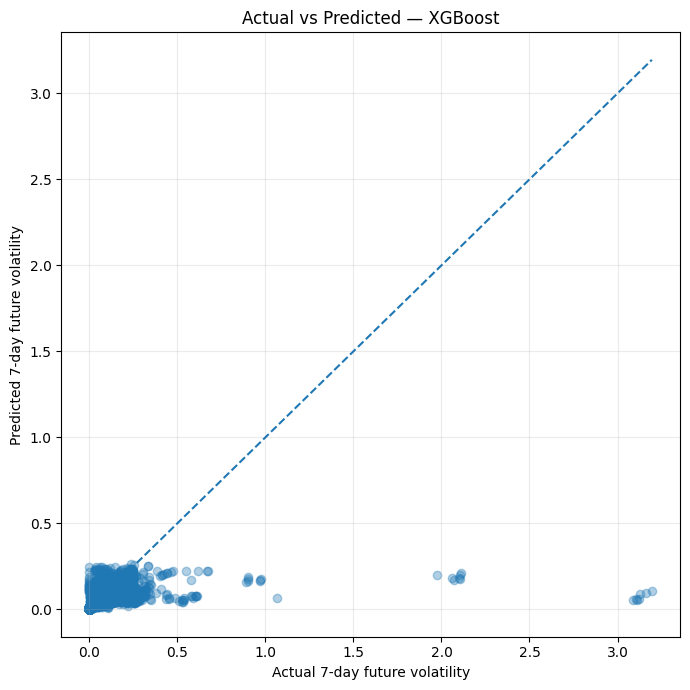

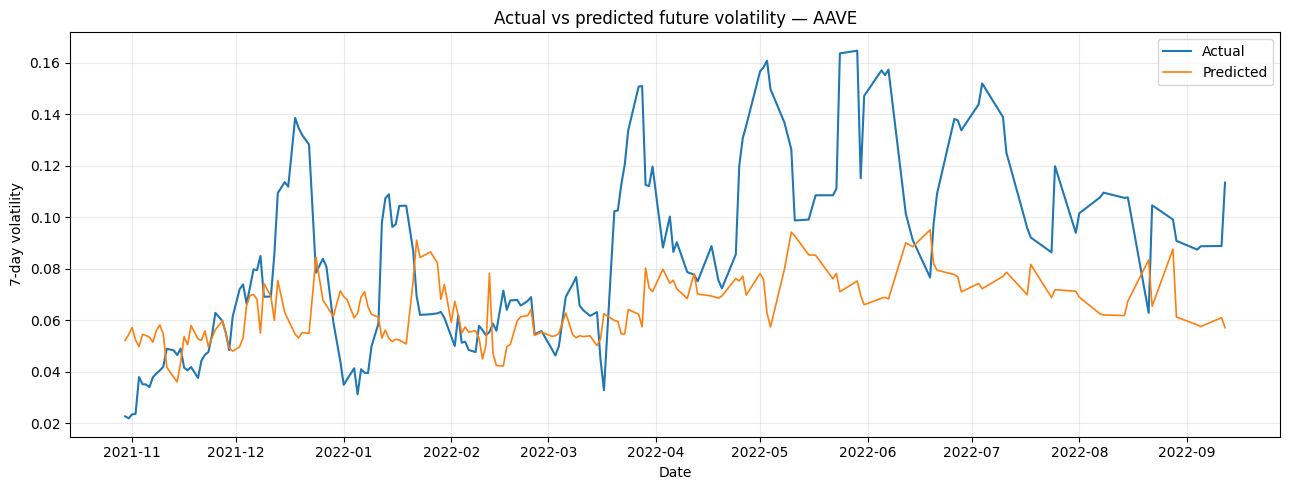

In [14]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test, test_predictions, alpha=0.35)
lower = min(float(y_test.min()), float(np.min(test_predictions)))
upper = max(float(y_test.max()), float(np.max(test_predictions)))
plt.plot([lower, upper], [lower, upper], linestyle="--")
plt.xlabel("Actual 7-day future volatility")
plt.ylabel("Predicted 7-day future volatility")
plt.title(f"Actual vs Predicted — {best_name}")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Show a chronological sample of predictions
plot_frame = data.loc[X_test.index, ["date", "crypto_name"]].copy()
plot_frame["actual"] = y_test
plot_frame["predicted"] = test_predictions
asset_to_plot = plot_frame["crypto_name"].iloc[0]
sample = plot_frame[plot_frame["crypto_name"] == asset_to_plot].sort_values("date").tail(180)

plt.figure(figsize=(13, 5))
plt.plot(sample["date"], sample["actual"], label="Actual", linewidth=1.5)
plt.plot(sample["date"], sample["predicted"], label="Predicted", linewidth=1.2)
plt.title(f"Actual vs predicted future volatility — {asset_to_plot}")
plt.xlabel("Date")
plt.ylabel("7-day volatility")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 11. Residual analysis

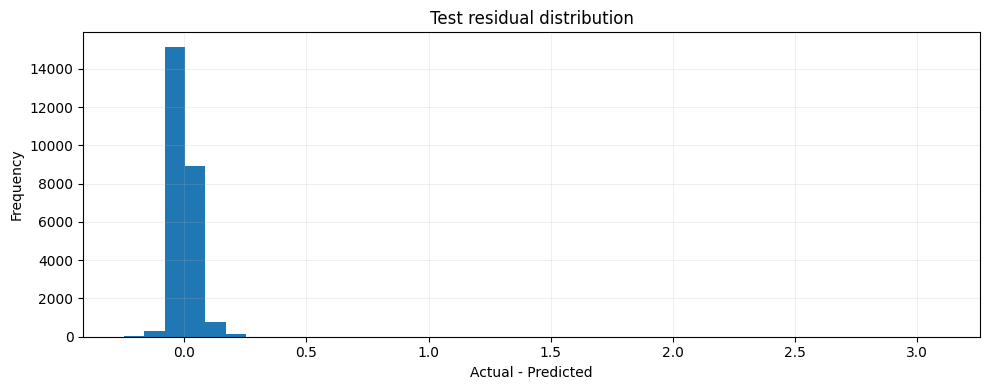

Mean residual: 0.00552217383343494
Residual standard deviation: 0.07420389686215552


In [15]:
residuals = y_test.values - test_predictions

plt.figure(figsize=(10, 4))
plt.hist(residuals, bins=40)
plt.title("Test residual distribution")
plt.xlabel("Actual - Predicted")
plt.ylabel("Frequency")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("Mean residual:", float(np.mean(residuals)))
print("Residual standard deviation:", float(np.std(residuals)))

## 12. Save the trained model and project artifacts

In [16]:
model_path = MODEL_DIR / "crypto_volatility_model.joblib"
joblib.dump(best_model, model_path)

metadata = {
    "selected_model": best_name,
    "target": "target_volatility_7d",
    "forecast_horizon_days": 7,
    "feature_columns": feature_cols,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "test_metrics": test_metrics,
    "train_end_date": str(pd.Timestamp(train_end).date()),
    "validation_end_date": str(pd.Timestamp(valid_end).date())
}
joblib.dump(metadata, MODEL_DIR / "crypto_volatility_metadata.joblib")

validation_results.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)
comparison.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)

print("Saved model:", model_path.resolve())
print("Saved metadata:", (MODEL_DIR / "crypto_volatility_metadata.joblib").resolve())
print("Saved evaluation files in:", OUTPUT_DIR.resolve())

Saved model: C:\Users\Mayur\CRYPTOCURRECNY VOLATILITY PROJECT\notebook\models\crypto_volatility_model.joblib
Saved metadata: C:\Users\Mayur\CRYPTOCURRECNY VOLATILITY PROJECT\notebook\models\crypto_volatility_metadata.joblib
Saved evaluation files in: C:\Users\Mayur\CRYPTOCURRECNY VOLATILITY PROJECT\notebook\artifacts


## 13. Load the model and make a prediction

In [17]:
# Demonstration: reload the saved model and predict the held-out test rows.
loaded_model = joblib.load(model_path)
reloaded_predictions = loaded_model.predict(X_test.iloc[:5])

demo = data.loc[X_test.index[:5], ["date", "crypto_name"]].copy()
demo["predicted_next_7d_volatility"] = reloaded_predictions
display(demo)

print("The prediction is a volatility estimate (standard deviation of the next 7 daily log returns), not a price forecast.")

,date,crypto_name,predicted_next_7d_volatility
53,2020-11-25,AAVE,0.080181
54,2020-11-26,AAVE,0.077393
55,2020-11-27,AAVE,0.080231
56,2020-11-29,AAVE,0.080306
57,2020-11-30,AAVE,0.091460


The prediction is a volatility estimate (standard deviation of the next 7 daily log returns), not a price forecast.


## 14. Important interpretation and next steps

- **Lower MAE/RMSE is better.** R² measures how much variation in the target is explained by the model; it can be negative on a difficult future test period.
- This is a volatility forecasting model, **not** a cryptocurrency price predictor or trading recommendation.
- The chronological split is essential. Do not randomly shuffle time-series rows.
- The target uses the next seven returns. Do not accidentally use future prices or future rolling indicators as input features.
- For a stronger experiment, compare against a simple baseline such as predicting the latest historical 7-day volatility, tune hyperparameters using validation dates only, and test on a later untouched period.
- Before deploying through FastAPI, ensure inference uses exactly the same feature calculations and column names as this notebook.

### Troubleshooting
- `FileNotFoundError`: update `DATA_PATH` to your CSV location.
- Missing columns: inspect the raw CSV headers and adjust the column mapping in Section 3.
- XGBoost missing: run `pip install xgboost` in the notebook environment, then restart the kernel.
- Too few dates: use a dataset with a longer daily history.


In [20]:
# Generate features using the notebook's existing function
featured_data = (
    df.groupby("crypto_name", group_keys=False)
      .apply(add_features)
)

# Get the latest available row for each cryptocurrency
latest_data = (
    featured_data.sort_values("date")
    .groupby("crypto_name")
    .tail(1)
    .copy()
)

# Select exactly the 31 features used during training
X_live = latest_data[metadata["feature_columns"]]

# Predict future 7-day volatility
predictions = model.predict(X_live)

# Display results
results = latest_data[["date", "crypto_name", "close"]].copy()
results["predicted_volatility_7d"] = predictions

display(results)

,date,crypto_name,close,predicted_volatility_7d
62779,2022-10-23,TONCOIN,1.404507,0.068971
46529,2022-10-23,POLKADOT,5.960239,0.048088
64997,2022-10-23,UNISWAP,6.285018,0.057413
67304,2022-10-23,USD COIN,1.000030,0.002468
62538,2022-10-23,THORCHAIN,1.484639,0.061779
66038,2022-10-23,UNUS SED LEO,4.158306,0.031557
61560,2022-10-23,THETA NETWORK,1.020839,0.055398
48918,2022-10-23,QUANT,175.486745,0.106168
60030,2022-10-23,THE SANDBOX,0.760992,0.054452
50396,2022-10-23,RAVENCOIN,0.031698,0.077478
